# Zonas, excedentes y escenarios — Valle del Cauca (arendonc2)

Notebook reproducible de las tareas **#2 (zonas)**, **#3 (excedentes)** y
**#4 (escenarios)** de Alejandro Rendón Correa.

Ejecuta de arriba a abajo. Requiere haber instalado `requirements.txt` y, la
primera vez, acceso a internet para descargar GADM y la población DANE.


In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "arendonc2").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from arendonc2 import common, descargar_geometrias, poblacion, zonas_acopio, excedentes, escenarios
cfg = common.cargar_config()
print("Raíz del repo:", ROOT)

Raíz del repo: /Users/alejo/Desktop/enfasis/proyecto/MingaData_PI


## 0. Insumos externos (GADM + población DANE)

In [2]:
descargar_geometrias.main()
poblacion.descargar()
pob = poblacion.generar(cfg["excedentes"]["anios"])
pob.head()

Ya existe: /Users/alejo/Desktop/enfasis/proyecto/MingaData_PI/data/raw/geo/gadm41_COL_2.json.zip (1,133,733 bytes)


Escrito /Users/alejo/Desktop/enfasis/proyecto/MingaData_PI/data/clean/poblacion_municipal.csv: 210 filas, 42 municipios, años [np.int64(2024), np.int64(2025), np.int64(2026), np.int64(2027), np.int64(2028)]


,cod_dane,municipio,anio,poblacion_total,fuente
0,76001,Cali,2024,2283846,DANE Proyecciones municipales por area 2020-20...
1,76001,Cali,2025,2285099,DANE Proyecciones municipales por area 2020-20...
2,76001,Cali,2026,2284775,DANE Proyecciones municipales por area 2020-20...
3,76001,Cali,2027,2283288,DANE Proyecciones municipales por area 2020-20...
4,76001,Cali,2028,2281367,DANE Proyecciones municipales por area 2020-20...


## 1. Tarea #2 — Zonas de acopio

Vecindad Queen + Ward con restricción de conectividad. Se evalúan k = 3..8 y se
publica k = 5 (configurable).

In [3]:
res_z = zonas_acopio.ejecutar(cfg, guardar=True)
print("Diagnóstico geometrías:", res_z["diagnostico_geometrias"])
print("Diagnóstico vecindad:", res_z["diagnostico_vecindad"])
res_z["metricas_k"]

Diagnóstico geometrías: {'n_municipios': 42, 'esperados': 42, 'geometrias_nulas': 0, 'cod_dane_duplicados': [], 'geometrias_invalidas': 0, 'municipios_sin_poligono': []}
Diagnóstico vecindad: {'n_componentes_conexas': 1, 'islas': [], 'min_vecinos': 1, 'max_vecinos': 9, 'promedio_vecinos': 4.29}


,k,todas_conexas,pct_zonas_conexas,inercia_intra,silhouette,tam_min,tam_max,oferta_min_cop,oferta_max_cop,oferta_cv,tiempo_prom_centro_min,tiempo_max_centro_min
0,3,True,100.0,51.141,0.3282,9,19,8.230815e+11,1.383012e+12,0.250,52.9,57.6
1,4,True,100.0,43.703,0.2516,7,14,3.460878e+11,1.383012e+12,0.515,51.2,66.1
2,5,True,100.0,37.804,0.2110,5,12,3.460878e+11,1.383012e+12,0.637,45.8,66.1
3,6,True,100.0,32.648,0.2217,4,9,1.027062e+11,1.383012e+12,0.809,49.4,84.2
4,7,True,100.0,27.592,0.1732,1,9,1.769094e+10,1.365321e+12,0.946,42.4,84.2
5,8,True,100.0,24.458,0.1907,1,9,1.769094e+10,7.330398e+11,0.613,37.4,84.2


In [4]:
zonas = res_z["zonas"]
print("42 municipios únicos:", zonas["cod_dane"].nunique())
print("Un centro por zona:", (zonas.groupby("zona")["es_centro_zona"].sum() == 1).all())
zonas.groupby("zona")["municipio"].apply(list)

42 municipios únicos: 42
Un centro por zona: True


zona
Z1    [Cali, Buenaventura, Buga, Candelaria, El Cerr...
Z2    [Alcalá, Cartago, El Dovio, La Unión, La Victo...
Z3    [Andalucia, Bolivar, Bugalagrande, Caicedonia,...
Z4    [Calima Darién, Dagua, Guacarí, La Cumbre, Res...
Z5    [Ansermanuevo, Argelia, El Aguila, El Cairo, V...
Name: municipio, dtype: object

### Mapa de zonas

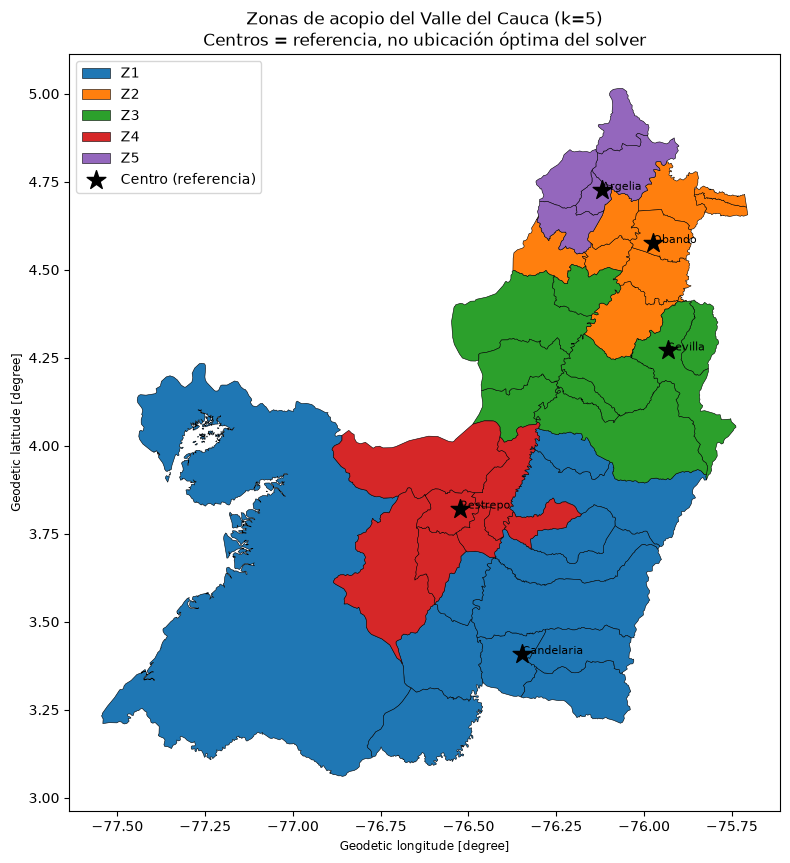

In [5]:
import geopandas as gpd
import matplotlib.pyplot as plt
mz = gpd.read_file(common.DATA_RES_OUT / "municipios_zonas_geometrias.geojson")
fig, ax = plt.subplots(figsize=(8, 10))
mz.plot(column="zona", ax=ax, legend=True, edgecolor="black", linewidth=0.4, cmap="tab10")
# centros de zona
mun = common.leer_municipios_coordenadas()
cent = zonas[zonas["es_centro_zona"] == 1].merge(mun, on="cod_dane", suffixes=("", "_c"))
ax.scatter(cent["lon"], cent["lat"], c="black", marker="*", s=200, label="Centro (referencia)")
for _, r in cent.iterrows():
    ax.annotate(r["municipio"], (r["lon"], r["lat"]), fontsize=8)
ax.set_title("Zonas de acopio del Valle del Cauca (k=5)\nCentros = referencia, no ubicación óptima del solver")
ax.legend()
plt.tight_layout()
plt.savefig(common.DATA_RES_OUT / "mapa_zonas.png", dpi=120)
plt.show()

## 2. Tarea #3 — Excedentes

9 combinaciones (oferta × consumo) por producto, municipio y año. Consumo desde
FAOSTAT (reparto por producción 2019–2023), población DANE (total municipal).

In [6]:
res_e = excedentes.ejecutar(cfg, guardar=True)
exc = res_e["excedentes"]
print("Filas:", len(exc), "| Excedentes negativos:", (exc["excedente_t"] < 0).sum())
print("Pendientes:", res_e["pendientes"]["producto"].tolist())
res_e["cobertura"].head(9)

Filas: 31230 | Excedentes negativos: 0
Pendientes: ['Ají', 'Aromáticas', 'Cacao', 'Café', 'Caña panelera', 'Cebolla Larga', 'Coco', 'Flores y follajes', 'Macadamia', 'Sacha Inchi', 'Stevia', 'Sábila', 'Té']


,anio,escenario_oferta,escenario_consumo,oferta_total_t,oferta_con_consumo_t,oferta_pendiente_consumo_t,pct_oferta_con_consumo,excedente_total_t
0,2024,alto,alto,2178822.15,1737557.54,441264.61,79.75,2001636.68
1,2024,alto,bajo,2178822.15,1737557.54,441264.61,79.75,2041269.95
2,2024,alto,base,2178822.15,1737557.54,441264.61,79.75,2021172.10
3,2024,bajo,alto,719607.68,557124.14,162483.54,77.42,606138.55
4,2024,bajo,bajo,719607.68,557124.14,162483.54,77.42,631829.66
5,2024,bajo,base,719607.68,557124.14,162483.54,77.42,617966.90
6,2024,base,alto,1301865.41,961008.22,340857.19,73.82,1160782.21
7,2024,base,bajo,1301865.41,961008.22,340857.19,73.82,1193826.92
8,2024,base,base,1301865.41,961008.22,340857.19,73.82,1176891.32


In [7]:
# Cuotas de reparto (ejemplo Fruits, other)
cu = res_e["cuotas"]
cu[cu["item_o_categoria"] == "Fruits, other"].sort_values("cuota", ascending=False).head(10)

,producto,tipo_mapeo,item_o_categoria,cuota,prod_2019_2023,nota
0,Aguacate,reparto_categoria,"Fruits, other",0.454996,360399.61,Fruta fresca. FAOSTAT no reporta aguacate per ...
1,Papaya,reparto_categoria,"Fruits, other",0.106987,84743.89,Fruta fresca.
2,Lulo,reparto_categoria,"Fruits, other",0.106754,84559.42,Fruta fresca.
3,Guayaba,reparto_categoria,"Fruits, other",0.086871,68810.42,Fruta fresca.
4,Maracuyá,reparto_categoria,"Fruits, other",0.073901,58536.85,Fruta fresca.
5,Borojó,reparto_categoria,"Fruits, other",0.033529,26558.00,Fruta fresca.
6,Guanábana,reparto_categoria,"Fruits, other",0.031800,25188.21,Fruta fresca.
7,Mora,reparto_categoria,"Fruits, other",0.027880,22083.98,Fruta fresca.
8,Mango,reparto_categoria,"Fruits, other",0.020387,16148.20,Fruta fresca.
9,Chontaduro,reparto_categoria,"Fruits, other",0.019342,15321.00,Fruto fresco.


In [8]:
# Excedente por zona (escenario base/base, 2024)
pz = res_e["por_zona"]
pz[(pz["anio"] == 2024) & (pz["escenario_oferta"] == "base") & (pz["escenario_consumo"] == "base")] \
    .groupby("zona")["excedente_t"].sum()

zona
Z1    160914.941658
Z2    132670.245509
Z3    481497.404275
Z4    235431.618798
Z5    166377.106038
Name: excedente_t, dtype: float64

## 3. Tarea #4 — Escenarios para optimización

27 combinaciones por año (oferta × consumo × mezcla), filas por zona.

In [9]:
df_esc = escenarios.ejecutar(cfg, guardar=True)
print("Combinaciones por año:", df_esc.groupby("anio")["id_escenario"].nunique().unique())
df_esc["suma"] = df_esc["volumen_nacional"] + df_esc["volumen_exportacion"]
df_esc.head(10)

Combinaciones por año: [27]


,id_escenario,oferta,consumo,pct_nacional,pct_exportacion,zona,volumen_nacional,volumen_exportacion,anio,alcance,cobertura_oferta_pct,suma
0,2024_Oalto_Calto_M20_80,alto,alto,0.2,0.8,Z1,49318.6842,197274.7370,2024,productos_alimentarios_con_equivalencia_FAOSTAT,54.30,246593.4212
1,2024_Oalto_Calto_M20_80,alto,alto,0.2,0.8,Z2,46139.0679,184556.2717,2024,productos_alimentarios_con_equivalencia_FAOSTAT,77.38,230695.3396
2,2024_Oalto_Calto_M20_80,alto,alto,0.2,0.8,Z3,171272.3907,685089.5627,2024,productos_alimentarios_con_equivalencia_FAOSTAT,89.78,856361.9534
3,2024_Oalto_Calto_M20_80,alto,alto,0.2,0.8,Z4,80278.5441,321114.1765,2024,productos_alimentarios_con_equivalencia_FAOSTAT,82.36,401392.7206
4,2024_Oalto_Calto_M20_80,alto,alto,0.2,0.8,Z5,53318.6499,213274.5994,2024,productos_alimentarios_con_equivalencia_FAOSTAT,73.69,266593.2493
5,2024_Oalto_Calto_M50_50,alto,alto,0.5,0.5,Z1,123296.7106,123296.7106,2024,productos_alimentarios_con_equivalencia_FAOSTAT,54.30,246593.4212
6,2024_Oalto_Calto_M50_50,alto,alto,0.5,0.5,Z2,115347.6698,115347.6698,2024,productos_alimentarios_con_equivalencia_FAOSTAT,77.38,230695.3396
7,2024_Oalto_Calto_M50_50,alto,alto,0.5,0.5,Z3,428180.9767,428180.9767,2024,productos_alimentarios_con_equivalencia_FAOSTAT,89.78,856361.9534
8,2024_Oalto_Calto_M50_50,alto,alto,0.5,0.5,Z4,200696.3603,200696.3603,2024,productos_alimentarios_con_equivalencia_FAOSTAT,82.36,401392.7206
9,2024_Oalto_Calto_M50_50,alto,alto,0.5,0.5,Z5,133296.6246,133296.6246,2024,productos_alimentarios_con_equivalencia_FAOSTAT,73.69,266593.2492


## 4. Adaptador para el solver de Samuel

In [10]:
from arendonc2.adaptador import preparar_para_solver, listar_escenarios
print(listar_escenarios(2024).head())
pkg = preparar_para_solver("2024_Obase_Cbase_M80_20", 2024)
print("Año:", pkg.anio, "| Cobertura:", pkg.cobertura_oferta_pct, "% | parcial:", pkg.cobertura_parcial)
print("Advertencias:", pkg.advertencias)
pkg.volumen_por_zona

              id_escenario  anio oferta consumo  pct_nacional  pct_exportacion
0  2024_Oalto_Calto_M20_80  2024   alto    alto           0.2              0.8
1  2024_Oalto_Calto_M50_50  2024   alto    alto           0.5              0.5
2  2024_Oalto_Calto_M80_20  2024   alto    alto           0.8              0.2
3  2024_Oalto_Cbajo_M20_80  2024   alto    bajo           0.2              0.8
4  2024_Oalto_Cbajo_M50_50  2024   alto    bajo           0.5              0.5
Año: 2024 | Cobertura: 73.82 % | parcial: True
Advertencias: ['Cobertura parcial: 73.82% de la oferta tiene consumo definido; el resto son productos sin equivalencia FAOSTAT (ver pendientes).']


,zona,volumen_nacional,volumen_exportacion,excedente_t
0,Z1,128731.9533,32182.9883,160914.9416
1,Z2,106136.1964,26534.0491,132670.2455
2,Z3,385197.9234,96299.4809,481497.4043
3,Z4,188345.2950,47086.3238,235431.6188
4,Z5,133101.6848,33275.4212,166377.1060


## 5. Lectura

- Las 5 zonas son contiguas (100 %) y agrupan los 42 municipios una sola vez.
- El excedente se concentra en las zonas productoras del norte y centro; Cali y los
  municipios urbanos aportan poco excedente porque su consumo local supera su oferta.
- Las mezclas nacional/exportación son **sensibilidad**, no participaciones
  observadas (ver `docs/arendonc2/escenarios_definicion.md`).
- Los centros de zona son referencias para recolección, **no** la ubicación óptima
  de la central: eso lo decide el modelo de Samuel.
